# TAM400: VPN or NonVPN Traffic Classification
## Revised experiment: controlling Random Forest complexity

**Student 1:** Shucayb AHmed Said | **Student 2:** Ayub Ali Barre | **Group:** 17

**Research question:** Can nine numerical flow measurements distinguish VPN from NonVPN traffic, and can tuning reduce the forest's training-validation gap?

Open this notebook in Google Colab and use **Runtime > Run all** on a CPU runtime. The complete experiment is here: raw-data download, cleaning, exploration, model training, cross-validation, tuning, test evaluation and final results. The search fits 64 parameter combinations across three folds, so it is slower than the earlier version. A GPU is not needed.

The included outputs come from a fresh local execution of this revised notebook. Running every cell in Colab recomputes all results. No saved model, separate notebook or external results file is loaded. Library versions are printed below.

The target is **NonVPN = 0** or **VPN = 1**. Each row is a network flow. This is an offline experiment, not a detector for the computer's current connection.

## 1. Import the libraries
These libraries are normally available in Colab. The first cell installs a library only if it is missing.

In [1]:
import importlib.util
import subprocess
import sys

packages = {"sklearn": "scikit-learn", "pandas": "pandas",
            "numpy": "numpy", "matplotlib": "matplotlib"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

from pathlib import Path
from io import StringIO
from urllib.request import urlretrieve
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
from sklearn.base import clone
print("matplotlib:", __import__("matplotlib").__version__)

Python: 3.12.14
scikit-learn: 1.6.1
pandas: 2.2.3
NumPy: 2.1.3
matplotlib: 3.10.7


## 2. Download and inspect the raw dataset
We use the ISCXVPN2016 dataset described by the **Canadian Institute for Cybersecurity at the University of New Brunswick, Canada**. It contains labelled traffic recorded with and without a VPN. The original university description and paper explain how the data was collected.

- **Original dataset source:** https://www.unb.ca/cic/datasets/vpn.html
- **Research paper:** https://doi.org/10.5220/0005740704070414
- **Exact feature-file copy used here:** https://github.com/shafwanur/thd-ss25-ml-project/blob/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff

Our code downloads this fixed public copy of the feature file for a 15-second flow timeout. Only the **raw data** is downloaded. The checksum checks that we have the expected copy each time. It does **not** verify that the copy is identical to the university archive. The official download route leads to a registration form. We have not independently compared our copy with that archive.

ARFF files have a header followed by comma-separated data rows. `class1` contains the original application labels.

In [2]:
url = "https://raw.githubusercontent.com/shafwanur/thd-ss25-ml-project/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff"
expected_hash = "8b12e8c0cd49f56af28cdaa7c2aa7795ee24de0b1bedf638280e00404f7c1563"
data_file = Path("15s.arff")
if not data_file.exists():
    urlretrieve(url, data_file)
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == expected_hash, "Unexpected dataset file"

# Read the ARFF column names and then its data rows.
lines = data_file.read_text().splitlines()
columns = [line.split()[1] for line in lines if line.upper().startswith("@ATTRIBUTE")]
start = next(i for i, line in enumerate(lines) if line.upper().startswith("@DATA")) + 1
df = pd.read_csv(StringIO("\n".join(lines[start:])), names=columns)
print("Raw rows and columns:", df.shape)
display(df.head())

Raw rows and columns: (18758, 24)


,duration,total_fiat,total_biat,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,flowBytesPerSecond,min_flowiat,max_flowiat,mean_flowiat,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,class1
0,9368711,16,4,1564818,1549373,190205.285714,203290.456522,389822.391917,370323.719754,10.353612,4802.688438,4,1523088,97590.739583,267600.198443,1871488,1.983656e+06,2195089,1.832197e+05,1234883,1420565.0,1523088,161096.539275,CHAT
1,7340238,18,4,1567554,1527893,165686.977273,186914.846154,317267.548742,304370.651301,11.580006,4340.186245,4,1517774,87383.785714,221462.862028,1491627,3.572433e+06,5653239,2.942704e+06,1131498,1324636.0,1517774,273138.379008,CHAT
2,4644225,29,15,1270547,1079974,165865.178571,195302.130435,329473.126261,300492.588227,11.412022,4161.512416,15,1079974,89312.019231,217475.425246,1758922,1.758922e+06,1758922,0.000000e+00,1079974,1079974.0,1079974,0.000000,CHAT
3,4978735,19,8,2492050,2457286,239543.250000,276596.388889,612435.304238,628339.573544,8.034169,3918.666087,8,2441990,127659.871795,436959.716436,1710925,2.382905e+06,3054885,9.503232e+05,1346073,1894031.5,2441990,774930.342317,CHAT
4,11838189,19,10,3094089,3093543,243766.500000,295954.725000,599721.781709,625632.703972,7.602514,2802.540152,10,3042717,133013.359551,436129.639296,1747431,2.400446e+06,3240696,6.232744e+05,1394455,1983227.0,3042717,725987.829075,CHAT


## 3. Create the inputs and target, then clean the data
We select nine numerical measurements to keep the project small. `class1` is used only to create the target; including it in the inputs would reveal the answer.

Negative durations and traffic rates are invalid, so we replace them with missing values. We first keep one copy of identical input-and-label rows. If an input vector still occurs more than once, it has conflicting labels, so we remove both versions. These cleaning rules are specific to this dataset.

In [3]:
features = ["duration", "flowPktsPerSecond", "flowBytesPerSecond",
            "min_flowiat", "max_flowiat", "mean_flowiat", "std_flowiat",
            "mean_active", "mean_idle"]
X = df[features].copy()
y = df["class1"].str.strip().str.upper().str.startswith("VPN-").astype(int).rename("vpn")

negative_cells = int((X < 0).sum().sum())
X[X < 0] = np.nan
clean = pd.concat([X, y], axis=1)
clean = clean.drop_duplicates()  # Keep one row when both inputs and label are identical.
clean = clean.drop_duplicates(subset=features, keep=False)  # Remove conflicting labels.
removed_rows = len(df) - len(clean)
X, y = clean[features], clean["vpn"]

print("Invalid negative cells replaced with missing values:", negative_cells)
print("Duplicate or conflicting rows removed:", removed_rows)
print("Clean rows:", len(clean))
print("Number of input features:", X.shape[1])

Invalid negative cells replaced with missing values: 1240
Duplicate or conflicting rows removed: 779
Clean rows: 17979
Number of input features: 9


## 4. Split the data and fix the experiment rules
We keep the same stratified 80/20 split and `random_state=42`. The training set has 14,383 flows and the test set has 3,596.

**Before the search:** use three stratified folds, use validation VPN F1 to identify candidates within one standard error of the highest mean F1, then choose the smallest fold-training/validation F1 gap. Break ties by higher mean validation F1, then the original grid order. The grid appears in section 11. This rule balances near-best validation F1 with a smaller training-validation gap. It is a practical heuristic, not a significance test. Test performance cannot change this choice.

All exploration, imputation fitting and tuning use training data only. After selection, evaluate the two forests together once on the test set and reuse those predictions for every table and figure. This test partition was examined in earlier project versions and in an initial strict-maximum-CV search. That first search still fitted the training folds nearly perfectly. The final selection rule was revised using training-fold diagnostics only and fixed before this final run. The test set remains a reused development test. This revision cannot make it an independent new test.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print("Training flows:", len(X_train))
print("Test flows:", len(X_test))
print("Training class counts (0 = NonVPN, 1 = VPN):")
print(y_train.value_counts().sort_index())

Training flows: 14383
Test flows: 3596
Training class counts (0 = NonVPN, 1 = VPN):
vpn
0    6927
1    7456
Name: count, dtype: int64


## 5. Explore the training data
Duration means the elapsed time between the first and last packet in a flow. **ISCXFlowMeter stores duration in microseconds.** Its original implementation documents the unit and divides duration by 1,000,000 when calculating packets per second:
https://github.com/ahlashkari/ISCXFlowMeter/blob/f3287486f114350b0b79dcfcf1050bc6a85190cf/src/main/java/iscx/cs/unb/ca/ifm/data/BasicFlow.java#L168-L172

For the histogram, divide by **1,000,000 to show seconds**. The full-range plot keeps the long flows. The second panel zooms to 0–15 seconds for readability and states how many flows are outside that view. It does not remove them from training. The file's 15-second timeout name is not a guarantee that every recorded duration is at most 15 seconds.

Many flows end quickly, while fewer last much longer. This produces a right-skewed distribution. The plots describe the observed distribution, not the applications responsible for it.

The Pearson table measures **linear** association with VPN=1. Low correlation does not mean that a feature is useless. Random Forest can learn nonlinear relationships and interactions between features. Keep all nine inputs. Only the graph uses seconds; the model inputs remain in their original units.

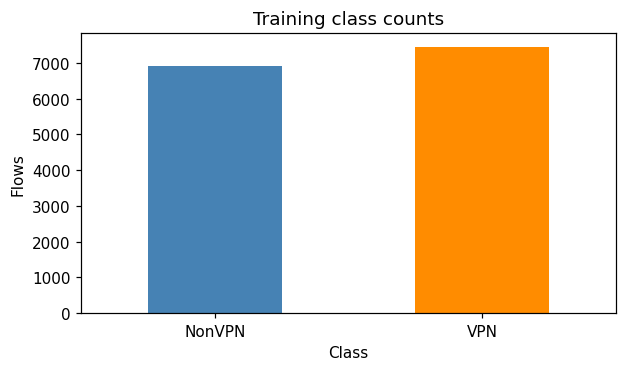

Training duration in seconds:


count    14383.000
mean        10.178
std         14.860
min          0.000
25%          0.692
50%         11.850
75%         14.960
95%         14.999
max        601.405
Name: duration, dtype: float64

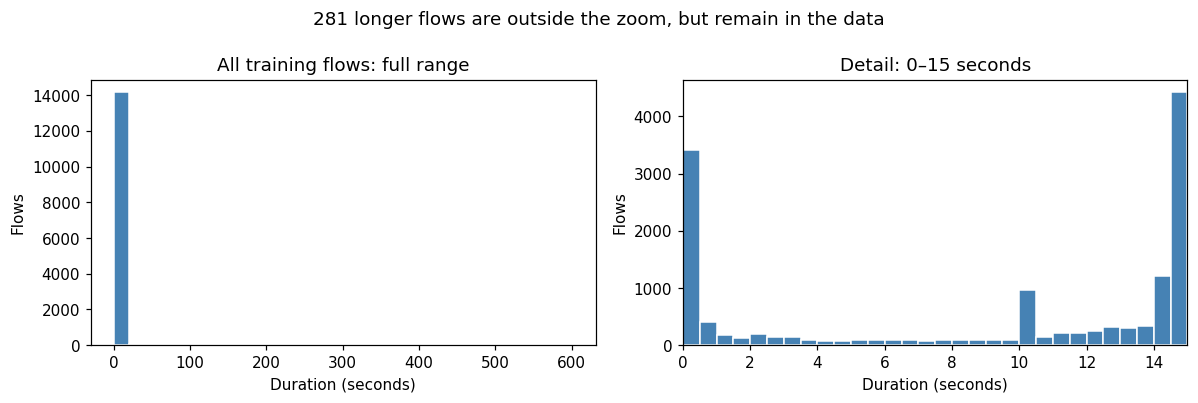

,Feature,Pearson correlation with VPN
0,mean_flowiat,0.0532
1,min_flowiat,0.0378
2,std_flowiat,0.0050
3,flowPktsPerSecond,0.0007
4,mean_active,-0.0077
5,max_flowiat,-0.0133
6,mean_idle,-0.0151
7,flowBytesPerSecond,-0.0347
8,duration,-0.0670


In [5]:
fig, ax = plt.subplots(figsize=(5.8, 3.5), num="class_counts")
y_train.value_counts().sort_index().plot.bar(ax=ax, color=["steelblue", "darkorange"])
ax.set(xticklabels=["NonVPN", "VPN"], xlabel="Class", ylabel="Flows", title="Training class counts")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

duration_seconds = X_train["duration"].dropna() / 1_000_000
duration_summary = duration_seconds.describe(percentiles=[0.25, 0.50, 0.75, 0.95])
print("Training duration in seconds:")
display(duration_summary.round(3))
outside_zoom = int((duration_seconds > 15).sum())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), num="duration_histogram")
axes[0].hist(duration_seconds, bins=30, color="steelblue", edgecolor="white")
axes[0].set(title="All training flows: full range", xlabel="Duration (seconds)", ylabel="Flows")
axes[1].hist(duration_seconds, bins=np.linspace(0, 15, 31), color="steelblue", edgecolor="white")
axes[1].set(title="Detail: 0–15 seconds", xlabel="Duration (seconds)", ylabel="Flows", xlim=(0, 15))
fig.suptitle(f"{outside_zoom:,} longer flows are outside the zoom, but remain in the data")
plt.tight_layout()
plt.show()

training_data = X_train.copy()
training_data["vpn"] = y_train
correlation_table = training_data.corr(numeric_only=True)["vpn"].drop("vpn").sort_values(ascending=False)
display(correlation_table.rename_axis("Feature").reset_index(name="Pearson correlation with VPN").round(4))

## 6. Train the baseline
We use `DummyClassifier` as our reference model. We call it the **baseline**. Our `strategy="most_frequent"` setting makes it predict the most common training class for every flow. This lets us check whether the other models improve on a simple prediction rule.

Every pipeline fits its median imputer on training data only. Keeping preprocessing inside the pipeline also protects the validation folds.

In [6]:
baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DummyClassifier(strategy="most_frequent"))
])
baseline.fit(X_train, y_train)
print("Baseline trained on", len(X_train), "flows.")

Baseline trained on 14383 flows.


## 7. Train SGDClassifier
`SGDClassifier` learns a linear decision boundary. We add `StandardScaler` because the numerical inputs have very different ranges. The scaler is fitted inside the pipeline.

In [7]:
sgd_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SGDClassifier(random_state=42))
])
sgd_model.fit(X_train, y_train)
print("SGDClassifier trained on", len(X_train), "flows.")

SGDClassifier trained on 14383 flows.


## 8. Train the default Random Forest
The default forest is the reference for the tuning experiment. It uses 100 trees, unlimited depth, at least two samples to split a node and one sample per leaf. `max_features="sqrt"` considers three of our nine features at each split. These flexible trees can fit the training set very closely.

We keep its default settings and `random_state=42`. The classifier does not need standard scaling. The median imputer is fitted within the pipeline.

In [8]:
forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(random_state=42))
])
forest_model.fit(X_train, y_train)
print("Random Forest trained on", len(X_train), "flows.")
print("Number of trees:", forest_model.named_steps["model"].n_estimators)

Random Forest trained on 14383 flows.
Number of trees: 100


## 9. Check full-training accuracy and F1
These predictions use data the fitted models have already seen. Report both accuracy and VPN F1. A high training score alone is not enough to diagnose overfitting. Next, compare training-fold F1 with validation-fold F1, using the same metric.

In [9]:
pipelines = {"Baseline": baseline, "SGDClassifier": sgd_model, "Default RF": forest_model}
training_rows = []
for name, model in pipelines.items():
    prediction = model.predict(X_train)
    training_rows.append({"Model": name,
                          "Training accuracy": accuracy_score(y_train, prediction),
                          "Training VPN F1": f1_score(y_train, prediction, zero_division=0)})
training_results = pd.DataFrame(training_rows)
display(training_results.round(4))

,Model,Training accuracy,Training VPN F1
0,Baseline,0.5184,0.6828
1,SGDClassifier,0.5893,0.6420
2,Default RF,0.9999,0.9999


## 10. Compare the initial models using training folds
Use three stratified folds within the training set. Each model trains on two folds and predicts the remaining fold, repeated three times. Preprocessing is fitted inside each training fold.

**VPN F1 is the selection metric.** Accuracy is also recorded, so accuracy gaps and F1 gaps can be calculated separately. `return_train_score=True` records each fold's training performance. The standard deviation describes variation across the three folds, not a confidence interval. No test rows enter these calculations.

,Model,CV training F1,CV F1 mean,CV F1 std,CV accuracy
2,Default RF,1.0000,0.8946,0.0062,0.8898
0,Baseline,0.6828,0.6828,0.0000,0.5184
1,SGDClassifier,0.6030,0.6003,0.0710,0.5922


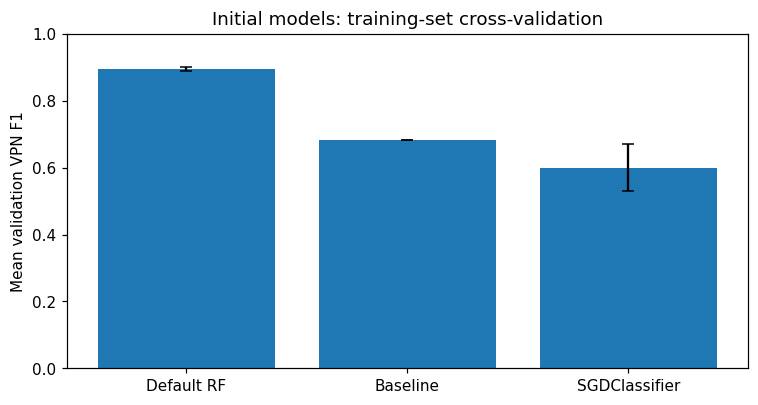

In [10]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = {"f1": "f1", "accuracy": "accuracy"}
cv_scores = {}
comparison_rows = []
for name, model in pipelines.items():
    scores = cross_validate(model, X_train, y_train, scoring=scoring, cv=cv,
                            return_train_score=True, n_jobs=2)
    cv_scores[name] = scores
    comparison_rows.append({
        "Model": name,
        "CV training F1": scores["train_f1"].mean(),
        "CV F1 mean": scores["test_f1"].mean(),
        "CV F1 std": scores["test_f1"].std(),
        "CV accuracy": scores["test_accuracy"].mean()})
comparison = pd.DataFrame(comparison_rows).sort_values("CV F1 mean", ascending=False)
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(7, 3.8), num="initial_comparison")
ax.bar(comparison["Model"], comparison["CV F1 mean"], yerr=comparison["CV F1 std"], capsize=4)
ax.set(ylim=(0, 1), ylabel="Mean validation VPN F1", title="Initial models: training-set cross-validation")
plt.tight_layout()
plt.show()

## 11. Tune tree complexity and select before testing
The fixed grid tests **64 combinations** with three folds each (192 cross-validation fits, followed by a refit of the best candidate). Keep 100 trees and no class weighting: the classes are fairly balanced, and this experiment focuses on controlling tree complexity.

| Parameter | Tested values | Meaning |
|---|---|---|
| `max_depth` | 10, 15, 20, None | Maximum number of levels in a tree |
| `min_samples_split` | 2, 10 | Minimum samples needed to split a node |
| `min_samples_leaf` | 1, 2, 4, 8 | Minimum samples in each final leaf |
| `max_features` | sqrt, 6 | Features considered at each split |

`GridSearchCV` evaluates all candidates on the training folds. The default configuration is included. We set `refit=False` so we can apply an explicit selection rule before fitting the final model:

1. Find the highest mean validation VPN F1 and its fold standard deviation.
2. Set the allowance to that standard deviation divided by the square root of three (one standard error).
3. Keep candidates with mean validation F1 at least the highest score minus that allowance.
4. Among these candidates, select the smallest mean fold-training F1 minus mean validation F1 gap. Break ties by higher validation F1, then original grid order.
5. Fit that selected candidate on all training rows.

This rule prefers a smaller gap while keeping validation F1 close to the best score. The allowance is a heuristic; three overlapping training folds do not establish statistical equivalence or a formal confidence interval.

The validation curve uses existing grid results. It varies leaf size while holding the other parameters at their selected values. It shows fold-training F1 and validation F1 with one standard deviation. It is a diagnostic of this search, not an independent validation result. A smaller gap is helpful only if validation performance remains strong.

The default and selected tuned forest are compared using cross-validation only. Freeze that choice before section 12. The highest CV score has some selection optimism because the same folds were used to search and compare.

Candidates evaluated: 64
Ten highest-scoring settings:


,max_depth,min_samples_split,min_samples_leaf,max_features,CV training F1,CV F1 mean,CV F1 std
32,20,2,1,sqrt,0.9999,0.8949,0.0047
48,None,2,1,sqrt,1.0000,0.8946,0.0062
56,None,2,1,6,1.0000,0.8937,0.0038
40,20,2,1,6,0.9997,0.8932,0.0027
33,20,10,1,sqrt,0.9774,0.8930,0.0037
58,None,2,2,6,0.9908,0.8930,0.0032
57,None,10,1,6,0.9803,0.8925,0.0022
24,15,2,1,6,0.9865,0.8924,0.0037
16,15,2,1,sqrt,0.9871,0.8924,0.0040
42,20,2,2,6,0.9896,0.8922,0.0024


Highest mean CV F1: 0.8949
One-standard-error allowance: 0.0027
Eligibility threshold: 0.8922
Eligible settings: 9
Selected parameters: {'model__max_depth': 20, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 10}


,Training accuracy,Training VPN F1,CV training F1,CV F1 mean,CV F1 std,CV accuracy,CV F1 gap
Model,,,,,,,
Default RF,0.9999,0.9999,1.0000,0.8946,0.0062,0.8898,0.1054
Tuned RF,0.9775,0.9784,0.9774,0.8930,0.0037,0.8876,0.0844


MODEL SELECTED BEFORE TEST EVALUATION: Tuned RF
Selection rule: within one SE of the highest CV F1, then smallest training-validation F1 gap.
Selected validation F1: 0.893


,param_model__min_samples_leaf,mean_train_f1,std_train_f1,mean_test_f1,std_test_f1
33,1,0.9774,0.0017,0.8930,0.0037
35,2,0.9710,0.0016,0.8914,0.0036
37,4,0.9616,0.0013,0.8893,0.0015
39,8,0.9363,0.0036,0.8819,0.0013


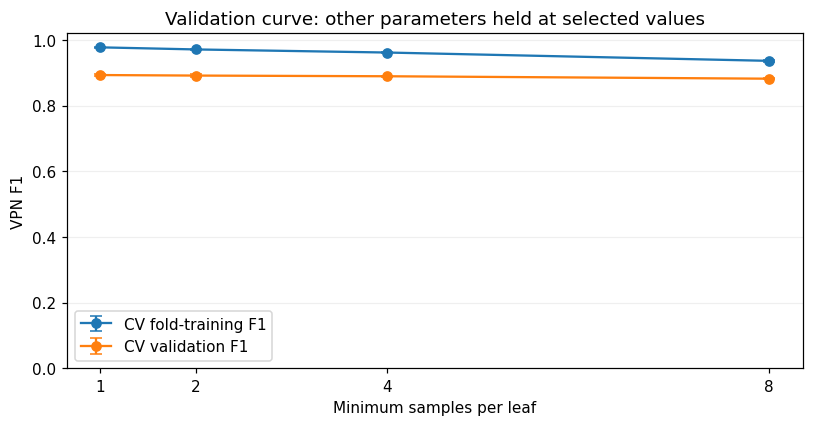

In [11]:
grid = {
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_split": [2, 10],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", 6]
}
search = GridSearchCV(forest_model, grid, scoring=scoring, refit=False, cv=cv,
                      return_train_score=True, n_jobs=2, error_score="raise")
search.fit(X_train, y_train)
tuning = pd.DataFrame(search.cv_results_)
peak_index = tuning["mean_test_f1"].idxmax()
peak_cv_f1 = float(tuning.loc[peak_index, "mean_test_f1"])
selection_allowance = float(tuning.loc[peak_index, "std_test_f1"] / np.sqrt(cv.get_n_splits()))
selection_threshold = peak_cv_f1 - selection_allowance
tuning["F1 gap"] = tuning["mean_train_f1"] - tuning["mean_test_f1"]
eligible = tuning.loc[tuning["mean_test_f1"] >= selection_threshold]
tuned_index = eligible.sort_values(["F1 gap", "mean_test_f1"], ascending=[True, False], kind="stable").index[0]
selected_params = tuning.loc[tuned_index, "params"]
tuned_model = clone(forest_model).set_params(**selected_params)
tuned_model.fit(X_train, y_train)
parameter_columns = ["param_" + name for name in grid]
tuning_table = tuning[parameter_columns + ["mean_train_f1", "mean_test_f1", "std_test_f1"]].copy()
tuning_table.columns = [name.replace("model__", "") for name in grid] + ["CV training F1", "CV F1 mean", "CV F1 std"]
print("Candidates evaluated:", len(tuning))
print("Ten highest-scoring settings:")
display(tuning_table.sort_values("CV F1 mean", ascending=False).head(10).round(4))
print("Highest mean CV F1:", round(peak_cv_f1, 4))
print("One-standard-error allowance:", round(selection_allowance, 4))
print("Eligibility threshold:", round(selection_threshold, 4))
print("Eligible settings:", len(eligible))
print("Selected parameters:", selected_params)

default_cv = comparison.set_index("Model").loc["Default RF"]
rf_models = {"Default RF": forest_model, "Tuned RF": tuned_model}
rf_rows = []
for name, model in rf_models.items():
    train_prediction = model.predict(X_train)
    is_tuned = name == "Tuned RF"
    rf_rows.append({
        "Model": name,
        "Training accuracy": accuracy_score(y_train, train_prediction),
        "Training VPN F1": f1_score(y_train, train_prediction),
        "CV training F1": tuning.loc[tuned_index, "mean_train_f1"] if is_tuned else default_cv["CV training F1"],
        "CV F1 mean": tuning.loc[tuned_index, "mean_test_f1"] if is_tuned else default_cv["CV F1 mean"],
        "CV F1 std": tuning.loc[tuned_index, "std_test_f1"] if is_tuned else default_cv["CV F1 std"],
        "CV accuracy": tuning.loc[tuned_index, "mean_test_accuracy"] if is_tuned else default_cv["CV accuracy"]})
rf_comparison = pd.DataFrame(rf_rows).set_index("Model")
rf_comparison["CV F1 gap"] = rf_comparison["CV training F1"] - rf_comparison["CV F1 mean"]
display(rf_comparison.round(4))

best_name = "Tuned RF"  # Selected by the fixed CV-only near-best/gap rule above.
final_model = rf_models[best_name]
best_cv_f1 = float(rf_comparison.loc[best_name, "CV F1 mean"])
print("MODEL SELECTED BEFORE TEST EVALUATION:", best_name)
print("Selection rule: within one SE of the highest CV F1, then smallest training-validation F1 gap.")
print("Selected validation F1:", round(best_cv_f1, 4))

curve_mask = pd.Series(True, index=tuning.index)
for parameter in ["model__max_depth", "model__min_samples_split", "model__max_features"]:
    value = selected_params[parameter]
    column = tuning["param_" + parameter]
    curve_mask &= column.isna() if value is None else column.eq(value)
validation_curve_table = tuning.loc[curve_mask, ["param_model__min_samples_leaf", "mean_train_f1", "std_train_f1", "mean_test_f1", "std_test_f1"]].sort_values("param_model__min_samples_leaf")
display(validation_curve_table.round(4))
leaf_sizes = validation_curve_table["param_model__min_samples_leaf"].astype(int)
fig, ax = plt.subplots(figsize=(7.5, 4), num="validation_curve")
ax.errorbar(leaf_sizes, validation_curve_table["mean_train_f1"], yerr=validation_curve_table["std_train_f1"], marker="o", capsize=4, label="CV fold-training F1")
ax.errorbar(leaf_sizes, validation_curve_table["mean_test_f1"], yerr=validation_curve_table["std_test_f1"], marker="o", capsize=4, label="CV validation F1")
ax.set(xlabel="Minimum samples per leaf", ylabel="VPN F1", xticks=[1, 2, 4, 8], ylim=(0, 1.02), title="Validation curve: other parameters held at selected values")
ax.legend(loc="lower left")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 12. Evaluate the two frozen forests once on the test set
The choice above is complete. Predict once with each forest, save those predictions in memory and reuse them below. Also evaluate the reference model for context. No test score is sent back to GridSearchCV or used to alter model selection.

Accuracy is the fraction of all correct predictions. VPN precision is the fraction of VPN predictions that are correct. VPN recall is the fraction of actual VPN flows found. VPN F1 combines precision and recall. ROC-AUC measures how well scores rank VPN above NonVPN flows.

Model,Default RF,Tuned RF
Training accuracy,0.9999,0.9775
Training VPN F1,0.9999,0.9784
CV training F1,1.0000,0.9774
CV F1 mean,0.8946,0.8930
CV F1 std,0.0062,0.0037
CV accuracy,0.8898,0.8876
CV F1 gap,0.1054,0.0844
Test accuracy,0.9066,0.9041
VPN precision,0.9008,0.8925
VPN recall,0.9211,0.9265


Reference model test results:


,Test accuracy,VPN precision,VPN recall,VPN F1,ROC-AUC
Model,,,,,
Baseline,0.5184,0.5184,1.0,0.6828,0.5


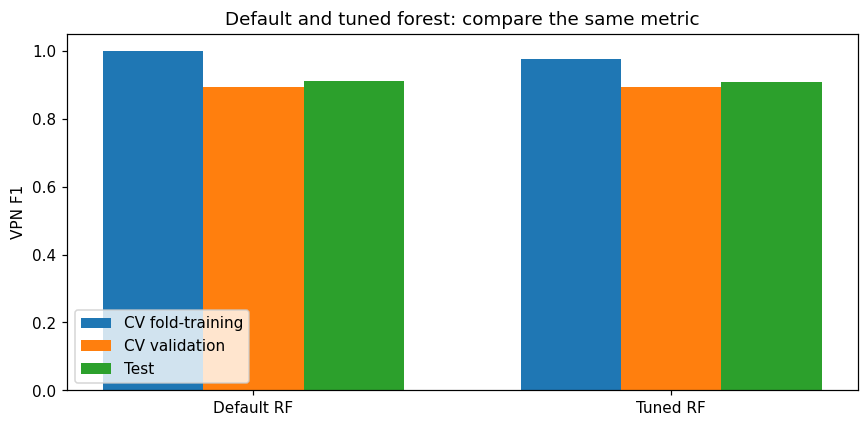

In [12]:
test_rows = []
test_predictions = {}
test_scores = {}
for name, model in {**rf_models, "Baseline": baseline}.items():
    prediction = model.predict(X_test)
    scores = model.predict_proba(X_test)[:, 1]
    test_predictions[name] = prediction
    test_scores[name] = scores
    test_rows.append({"Model": name,
                      "Test accuracy": accuracy_score(y_test, prediction),
                      "VPN precision": precision_score(y_test, prediction, zero_division=0),
                      "VPN recall": recall_score(y_test, prediction, zero_division=0),
                      "VPN F1": f1_score(y_test, prediction, zero_division=0),
                      "ROC-AUC": roc_auc_score(y_test, scores)})
results = pd.DataFrame(test_rows).set_index("Model")
final_comparison = rf_comparison.join(results)
final_comparison["Accuracy gap"] = final_comparison["Training accuracy"] - final_comparison["Test accuracy"]
display(final_comparison.T.round(4))
print("Reference model test results:")
display(results.loc[["Baseline"]].round(4))

fig, ax = plt.subplots(figsize=(8, 4), num="generalization_comparison")
x = np.arange(2)
width = 0.24
for offset, (column, label) in zip([-1, 0, 1], [("CV training F1", "CV fold-training"), ("CV F1 mean", "CV validation"), ("VPN F1", "Test")]):
    ax.bar(x + offset * width, final_comparison[column], width, label=label)
ax.set(xticks=x, xticklabels=final_comparison.index, ylabel="VPN F1", ylim=(0, 1.05), title="Default and tuned forest: compare the same metric")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 13. Compare both confusion matrices
Use the predictions saved in section 12. Rows show actual classes and columns show predicted classes. A false VPN alarm is NonVPN predicted as VPN. A missed VPN flow is VPN predicted as NonVPN.

Default RF | False VPN alarms: 189 | Missed VPN flows: 147
Tuned RF | False VPN alarms: 208 | Missed VPN flows: 137


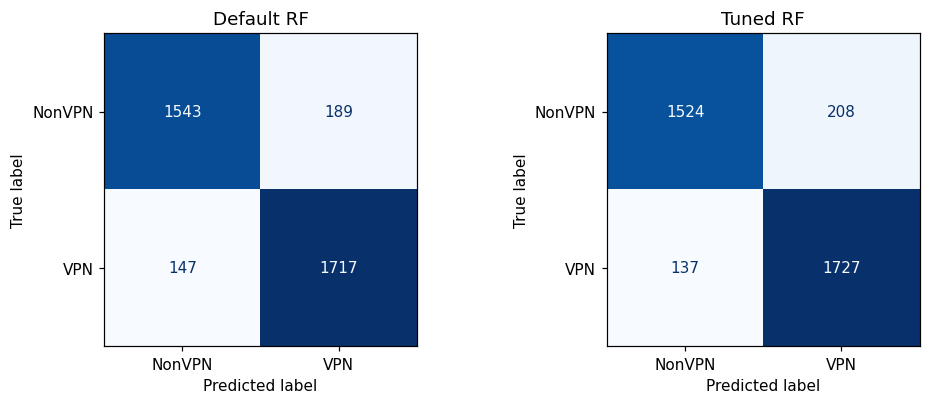

In [13]:
confusion_matrices = {}
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), num="confusion_matrices")
for ax, name in zip(axes, rf_models):
    matrix = confusion_matrix(y_test, test_predictions[name], labels=[0, 1])
    confusion_matrices[name] = matrix
    ConfusionMatrixDisplay(matrix, display_labels=["NonVPN", "VPN"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    print(name, "| False VPN alarms:", matrix[0, 1], "| Missed VPN flows:", matrix[1, 0])
plt.tight_layout()
plt.show()
final_prediction = test_predictions[best_name]

## 14. Compare example predictions with the true labels
These examples come from the test set. They demonstrate the predictions made by the model trained above; they do not inspect the current internet connection.

In [14]:
predictions = pd.DataFrame({
    "Source row": X_test.index,
    "Actual": np.where(y_test == 1, "VPN", "NonVPN"),
    "Predicted": np.where(final_prediction == 1, "VPN", "NonVPN")
})
display(predictions.head(10))

,Source row,Actual,Predicted
0,15291,VPN,NonVPN
1,4257,NonVPN,VPN
2,1260,NonVPN,NonVPN
3,2990,NonVPN,NonVPN
4,18400,NonVPN,NonVPN
5,8769,VPN,VPN
6,8271,VPN,VPN
7,9953,VPN,VPN
8,5218,NonVPN,NonVPN
9,886,NonVPN,VPN


## 15. Final comparison and interpretation from this run
These values are calculated from this run. The model name comes from the selection made before test evaluation. Lower training performance is only useful if validation performance remains strong. Compare the default and tuned models using F1 across training and validation, and accuracy across full training and test.

In [15]:
print("FINAL MODEL:", best_name)
print("Chosen before this run’s test evaluation using the CV-only near-best/gap rule.")
print("Selected parameters:", {name: final_model.named_steps["model"].get_params()[name] for name in ["n_estimators", "max_depth", "min_samples_split", "min_samples_leaf", "max_features"]})
display(final_comparison.T.round(4))
default = final_comparison.loc["Default RF"]
tuned = final_comparison.loc["Tuned RF"]
gap_reduction = default["CV F1 gap"] - tuned["CV F1 gap"]
accuracy_gap_reduction = default["Accuracy gap"] - tuned["Accuracy gap"]
print(f"Default to tuned CV F1 change: {tuned['CV F1 mean'] - default['CV F1 mean']:+.4f}")
print(f"Reduction in fold-training/validation F1 gap: {gap_reduction * 100:.2f} percentage points")
print(f"Reduction in full-training/test accuracy gap: {accuracy_gap_reduction * 100:.2f} percentage points")
if gap_reduction > 0 and tuned["CV F1 mean"] >= selection_threshold:
    print("Tuning reduced the training-validation F1 gap while keeping validation F1 within the predefined CV allowance.")
    print("This supports reduced overfitting in this experiment, not its elimination. Report any small validation-score decrease as a trade-off.")
else:
    print("This run does not meet the stated gap-reduction and near-best validation conditions. Report this outcome honestly.")
print("A fresh independent traffic capture is still needed to confirm generalization.")

FINAL MODEL: Tuned RF
Chosen before this run’s test evaluation using the CV-only near-best/gap rule.
Selected parameters: {'n_estimators': 100, 'max_depth': 20, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt'}


Model,Default RF,Tuned RF
Training accuracy,0.9999,0.9775
Training VPN F1,0.9999,0.9784
CV training F1,1.0000,0.9774
CV F1 mean,0.8946,0.8930
CV F1 std,0.0062,0.0037
CV accuracy,0.8898,0.8876
CV F1 gap,0.1054,0.0844
Test accuracy,0.9066,0.9041
VPN precision,0.9008,0.8925
VPN recall,0.9211,0.9265


Default to tuned CV F1 change: -0.0015
Reduction in fold-training/validation F1 gap: 2.11 percentage points
Reduction in full-training/test accuracy gap: 1.99 percentage points
Tuning reduced the training-validation F1 gap while keeping validation F1 within the predefined CV allowance.
This supports reduced overfitting in this experiment, not its elimination. Report any small validation-score decrease as a trade-off.
A fresh independent traffic capture is still needed to confirm generalization.


## 16. Interpretation and limitations
Use the measured comparison above to decide whether tuning helped. The validation curve shows the trade-off between fitting the training folds and predicting their held-out validation folds. We do not manually lower any training score. A reduction in training accuracy by itself would not prove improvement.

- Model selection uses the fixed CV-only near-best/gap rule, not test accuracy. The highest and selected CV scores are selection scores because the same folds informed the search and rule.
- The test partition was examined in previous versions and an initial strict-maximum-CV search. We revised the rule based on the training-fold diagnostics, then froze it before the final run. This is still a reused development test, not independent confirmation.
- Removing contradictory input vectors excludes some difficult observations. Results apply to this cleaned dataset.
- Session identifiers are unavailable, so related flows may occur in both partitions.
- The public data copy has not been independently compared with the original archive. The traffic is historical.
- Evaluate new traffic captures, separated by session or capture, before claiming performance in a new environment.

Save this notebook with its outputs so the complete experiment can be inspected in one file.

## 17. References and AI acknowledgment
1. G. Draper-Gil et al., *Characterization of Encrypted and VPN Traffic using Time-related Features*, ICISSP 2016, pp. 407–414. https://doi.org/10.5220/0005740704070414
2. Official ISCXVPN2016 dataset: https://www.unb.ca/cic/datasets/vpn.html
3. Exact feature-file copy: https://github.com/shafwanur/thd-ss25-ml-project/blob/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff
4. Duration unit in the original ISCXFlowMeter implementation: https://github.com/ahlashkari/ISCXFlowMeter/blob/f3287486f114350b0b79dcfcf1050bc6a85190cf/src/main/java/iscx/cs/unb/ca/ifm/data/BasicFlow.java#L168-L172
5. Random Forest: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
6. GridSearchCV: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
7. Project repository: https://github.com/SAS2005/VPN-NonVPN-Classification-project

OpenAI Codex helped with explanations, source research, code generation and debugging, running the experiment locally, figures and drafting. The saved outputs in this revised notebook are from that local execution. We are responsible for reviewing, understanding and explaining the submitted work.

**Shucayb's contribution:** [complete with actual work]  
**Ayub's contribution:** [complete with actual work]